# Lab 01: Simple Linear Regression — Salary Prediction

This laboratory project explores univariate linear regression using Ordinary Least Squares (OLS) to predict employee compensation based on age and professional experience.

### Objectives:
1. Exploratory Data Analysis (EDA) and summary statistics.
2. Data visualization: relationship between employee age and salary.
3. Fitting an Ordinary Least Squares (OLS) Linear Regression model.
4. Model evaluation using $R^2$ score and regression equation derivation.
5. Making predictions for unseen age profiles.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Load salary dataset
df = pd.read_csv("data.csv")
print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
display(df.head())


Dataset Shape: (250, 5)

First 5 records:


,age,experience,gender,profession,salary
0,56,35,Male,Consultant,397567
1,46,19,Female,Аға заңгер,363626
2,32,6,Male,IT Маман,244663
3,60,37,Male,Бас инженер,418776
4,25,3,Female,Accountant,274513


In [2]:
# Summary statistics
print("Summary Statistics:")
display(df.describe())


Summary Statistics:


,age,experience,salary
count,250.000000,250.00000,250.000000
mean,40.800000,17.56000,344645.592000
std,13.727409,12.85189,89236.489631
min,18.000000,0.00000,165887.000000
25%,28.250000,5.00000,271840.500000
50%,41.000000,17.00000,345678.000000
75%,53.000000,29.00000,418747.000000
max,64.000000,42.00000,529032.000000


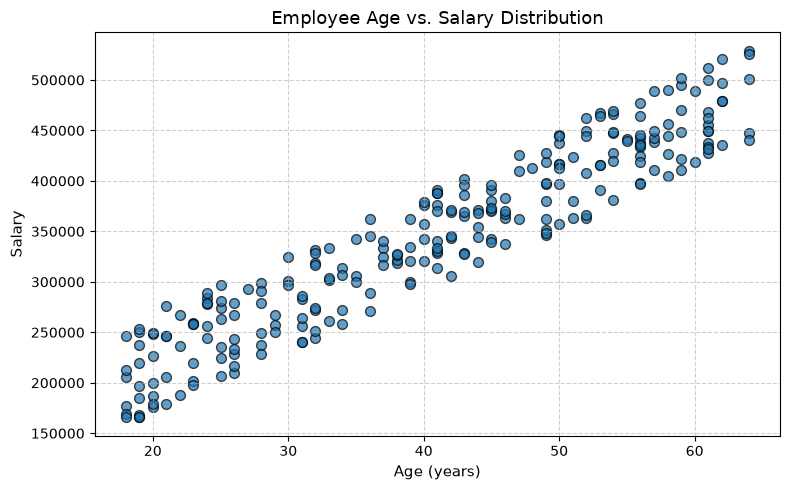

In [3]:
# Scatter plot: Age vs Salary
plt.figure(figsize=(8, 5))
plt.scatter(df["age"], df["salary"], color="#1f77b4", alpha=0.7, edgecolors="k", s=50)
plt.xlabel("Age (years)", fontsize=11)
plt.ylabel("Salary", fontsize=11)
plt.title("Employee Age vs. Salary Distribution", fontsize=13)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


In [4]:
# Prepare features and target
X = df[["age"]]
y = df["salary"]

# Fit Linear Regression model
model = LinearRegression()
model.fit(X, y)

b_0 = model.intercept_
b_1 = model.coef_[0]

print(f"Intercept (b0): {b_0:.2f}")
print(f"Slope (b1):     {b_1:.2f}")
print(f"Regression Equation: Salary = {b_0:.2f} + {b_1:.2f} * Age")


Intercept (b0): 94067.50
Slope (b1):     6141.62
Regression Equation: Salary = 94067.50 + 6141.62 * Age


In [5]:
# Compute predictions and evaluate R2
pred = model.predict(X)
r2 = r2_score(y, pred)
print(f"Coefficient of Determination (R²): {r2:.4f}")


Coefficient of Determination (R²): 0.8926


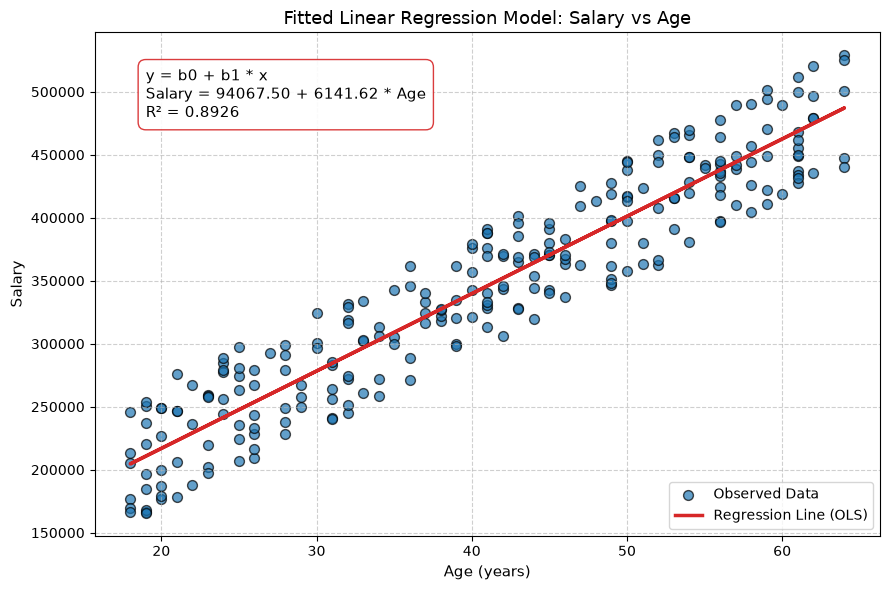

In [6]:
# Visualization of Regression Line with Equation
plt.figure(figsize=(9, 6))
plt.scatter(X, y, color="#1f77b4", alpha=0.7, edgecolors="k", s=50, label="Observed Data")
plt.plot(X, pred, color="#d62728", linewidth=2.5, label="Regression Line (OLS)")

formula_text = f"y = b0 + b1 * x\nSalary = {b_0:.2f} + {b_1:.2f} * Age\nR² = {r2:.4f}"
plt.text(19, 480000, formula_text, fontsize=11, 
         bbox=dict(facecolor='white', alpha=0.9, edgecolor='#d62728', boxstyle='round,pad=0.5'))

plt.xlabel("Age (years)", fontsize=11)
plt.ylabel("Salary", fontsize=11)
plt.title("Fitted Linear Regression Model: Salary vs Age", fontsize=13)
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


In [7]:
# Inference on a new sample: 25 years old
new_sample = pd.DataFrame({"age": [25]})
pred_25 = model.predict(new_sample)
print(f"Predicted salary for Age 25: {pred_25[0]:,.2f}")


Predicted salary for Age 25: 247,608.00


In [8]:
# Filter high earners
high_earners = df[df["salary"] > 350000]
print(f"Number of employees with salary > 350,000: {len(high_earners)}")
display(high_earners.head())


Number of employees with salary > 350,000: 122


,age,experience,gender,profession,salary
0,56,35,Male,Consultant,397567
1,46,19,Female,Аға заңгер,363626
3,60,37,Male,Бас инженер,418776
6,56,29,Female,Бас есепші,433453
8,40,14,Female,Аға заңгер,376260
